# Homework Reflection: Weeks 9-12

### Imports

In [40]:
from IPython.display import Image, display

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy import stats

### Homework Reflection 9

*1. Write some code that will use a simulation to estimate the standard deviation of the coefficient when there is heteroskedasticity. Compare these standard errors to those found via statsmodels OLS or a similar linear regression model.*

In [4]:
def repeated_ols_simulator_homo(
    num_samples=10,
    num_times=1000,
    beta_0=1.0,
    beta_1=2.0,
    x_sigma=2.0,
    hetero_intercept=1.0,
    hetero_slope=0.5,
    random_seed=42
):
    if num_samples < 3:
        print("Wrong setup: each OLS fit needs at least 3 samples to estimate residual variance.")
        return

    rng = np.random.default_rng(random_seed)

    beta_0_hats = np.empty(num_times)
    beta_1_hats = np.empty(num_times)
    se_beta_1_hats_sm_classical = np.empty(num_times)

    for t in range(num_times):
        X = rng.normal(loc=0.0, scale=x_sigma, size=num_samples)

        sigma_i = hetero_intercept + hetero_slope * np.abs(X)
        epsilon = rng.normal(loc=0.0, scale=1.0, size=num_samples) * sigma_i

        Y = beta_0 + beta_1 * X + epsilon

        X_mean = X.mean()
        Y_mean = Y.mean()
        Sxx = np.sum((X - X_mean) ** 2)

        if Sxx == 0:
            print("Wrong setup: OLS cannot estimate a slope because Var(X) is zero.")
            return

        beta_1_hat = np.sum((X - X_mean) * (Y - Y_mean)) / Sxx
        beta_0_hat = Y_mean - beta_1_hat * X_mean

        beta_0_hats[t] = beta_0_hat
        beta_1_hats[t] = beta_1_hat

        X_design = sm.add_constant(X)
        model = sm.OLS(Y, X_design).fit()
        se_beta_1_hats_sm_classical[t] = model.bse[1]


    beta_1_hat_sample_deviation = beta_1_hats.std(ddof=1)

    mean_se_beta_1_sm_classical = se_beta_1_hats_sm_classical.mean()

    print(f"{'Simulation'}: {beta_1_hat_sample_deviation:.4f}")
    print(f"{'statsmodels OLS'}: {mean_se_beta_1_sm_classical:.4f}")

    diff = abs(beta_1_hat_sample_deviation - mean_se_beta_1_sm_classical)
    avg = (beta_1_hat_sample_deviation + mean_se_beta_1_sm_classical) / 2
    pct_diff = (diff / avg) * 100

    print(f"% diff: {pct_diff:.0f}%")


repeated_ols_simulator_homo(
    num_samples=200,
    num_times=20000,
    beta_0=1.0,
    beta_1=2.0,
    x_sigma=2.0,
    hetero_intercept=1.0,
    hetero_slope=0.5,
    random_seed=42,
)

Simulation: 0.0953
statsmodels OLS: 0.0671
% diff: 35%


As demonstrated in the above function, the standard deviation of the coefficient is much different than that of the value computed by simulation. To be precise, in this scenario, there is an ~35% difference between the two values. The reason for this is that the standard OLS formula, as used by statsmodels, assumes homoscedasticity (constant variance). When there is heteroskedasticity, simulation is a better tool for the task at hand.

------

*2. Write some code that will use a simulation to estimate the standard deviation of the coefficient when errors are highly correlated / non-independent. Compare these standard errors to those found via statsmodels OlS or a similar linear regression model.*

In [5]:
def repeated_ols_simulator_hetero(
    num_samples=10,
    num_times=1000,
    beta_0=1.0,
    beta_1=2.0,
    x_sigma=2.0,
    hetero_intercept=1.0,
    hetero_slope=0.5,
    rho=0.8,
    random_seed=42
):
    if num_samples < 3:
        print("Wrong setup: each OLS fit needs at least 3 samples to estimate residual variance.")
        return

    rng = np.random.default_rng(random_seed)

    beta_0_hats = np.empty(num_times)
    beta_1_hats = np.empty(num_times)
    se_beta_1_hats_sm_classical = np.empty(num_times)

    for t in range(num_times):
        X = rng.normal(loc=0.0, scale=x_sigma, size=num_samples)

        sigma_i = hetero_intercept + hetero_slope * np.abs(X)

        common_shock = rng.normal(loc=0.0, scale=1.0)
        idio_noise = rng.normal(loc=0.0, scale=1.0, size=num_samples)
        z = np.sqrt(rho) * common_shock + np.sqrt(1 - rho) * idio_noise
        epsilon = z * sigma_i

        Y = beta_0 + beta_1 * X + epsilon

        X_mean = X.mean()
        Y_mean = Y.mean()
        Sxx = np.sum((X - X_mean) ** 2)

        if Sxx == 0:
            print("Wrong setup: OLS cannot estimate a slope because Var(X) is zero.")
            return

        beta_1_hat = np.sum((X - X_mean) * (Y - Y_mean)) / Sxx
        beta_0_hat = Y_mean - beta_1_hat * X_mean

        beta_0_hats[t] = beta_0_hat
        beta_1_hats[t] = beta_1_hat

        X_design = sm.add_constant(X)
        model = sm.OLS(Y, X_design).fit()
        se_beta_1_hats_sm_classical[t] = model.bse[1]

    beta_1_hat_sample_deviation = beta_1_hats.std(ddof=1)
    mean_se_beta_1_sm_classical = se_beta_1_hats_sm_classical.mean()

    print(f"{'Simulation'}: {beta_1_hat_sample_deviation:.4f}")
    print(f"{'statsmodels OLS'}: {mean_se_beta_1_sm_classical:.4f}")

    diff = abs(beta_1_hat_sample_deviation - mean_se_beta_1_sm_classical)
    avg = (beta_1_hat_sample_deviation + mean_se_beta_1_sm_classical) / 2
    pct_diff = (diff / avg) * 100

    print(f"% diff: {pct_diff:.0f}%")


repeated_ols_simulator_hetero(
    num_samples=200,
    num_times=20000,
    beta_0=1.0,
    beta_1=2.0,
    x_sigma=2.0,
    hetero_intercept=1.0,
    hetero_slope=0.5,
    rho=0.8,
    random_seed=42,
)

Simulation: 0.0538
statsmodels OLS: 0.0350
% diff: 42%


Similar to the case with heteroskedasticity, the OLS estimate is far off (49% difference). This is due to the fact that OLS assumes independence, as in uncorrelated error terms.

*Show that if the correlation between errors is high enough, then the estimated standard deviation of the coefficient, using bootstrap errors, might not match that found by a full simulation of the Data Generating Process.  (This can be fixed if you have a huge amount of data for the bootstrap simulation.)*

In [6]:
def bootstrap_vs_sim(
    num_samples=10,
    num_times=5000,
    num_boot=5000,
    beta_0=1.0,
    beta_1=2.0,
    x_sigma=2.0,
    hetero_intercept=1.0,
    hetero_slope=0.5,
    rho=0.9,
    random_seed=42,
):
    rng = np.random.default_rng(random_seed)

    def simulate(n):
        X = rng.normal(0.0, x_sigma, size=n)
        sigma_i = hetero_intercept + hetero_slope * np.abs(X)
        common_shock = rng.normal()
        idio = rng.normal(size=n)
        eps = (np.sqrt(rho) * common_shock + np.sqrt(1 - rho) * idio) * sigma_i
        return X, beta_0 + beta_1 * X + eps

    def beta1_hat(X, Y):
        return sm.OLS(Y, sm.add_constant(X)).fit().params[1]

    sim = np.array([beta1_hat(*simulate(num_samples)) for _ in range(num_times)])

    X_obs, Y_obs = simulate(num_samples)
    n = len(X_obs)
    boot = np.array([
        beta1_hat(X_obs[idx], Y_obs[idx])
        for idx in (rng.integers(0, n, n) for _ in range(num_boot))
    ])

    print(f"n={num_samples} sim_std={sim.std(ddof=1):.4f} boot_std={boot.std(ddof=1):.4f}")

bootstrap_vs_sim(num_samples=10, rho=0.9)
bootstrap_vs_sim(num_samples=100000, rho=0.9)

n=10 sim_std=0.2134 boot_std=0.0722
n=100000 sim_std=0.0020 boot_std=0.0022


We can see that when sampled only a few times, the standard errors are off by a significant margin. This is because bootstrapping requires a significant number of samples before it converges to a *ground truth*. When we sample it 100,000 times, we can see that the standard errors are almost identical.

---

### Homework Reflection 11

*1. Construct a dataset for an event study where the value, derivative, and second derivative of a trend all change discontinuously (suddenly) after an event. Build a model that tries to decide whether the event is real (has a nonzero effect) using:*

*(a) only the value,*\
*(b) the value, derivative, and second derivative.*


*Which of these models is better at detecting and/or quantifying the impact of the event?  (What might "better" mean here?)*

In [28]:
def compute_event_study_data(
    n_days=365,
    event_day=160,
    seed=7,

    value_intercept=100.0,
    value_noise=0.3,
    value_pre_slope=0.05,
    value_event_jump=0.6,
    value_post_slope_increase=0.03,
    value_post_second_derivative=0.0003,
):
    rng = np.random.default_rng(seed)

    t = np.arange(n_days)

    if event_day >= n_days:
        event_day = n_days - 1

    after_event = t >= event_day
    days_after_event = np.maximum(t - event_day, 0)

    value_value = (
        value_intercept
        + value_pre_slope * t
        + value_event_jump * after_event
        + value_post_slope_increase * days_after_event
        + value_post_second_derivative * days_after_event**2
        + rng.normal(0, value_noise, size=n_days)
    )

    value_value = np.maximum(value_value, 1)

    value_return = np.empty(n_days)
    value_return[0] = np.nan
    value_return[1:] = value_value[1:] / value_value[:-1] - 1

    return {
        "t": t,
        "event_day": event_day,
        "value_value": value_value,
        "value_return": value_return,
    }

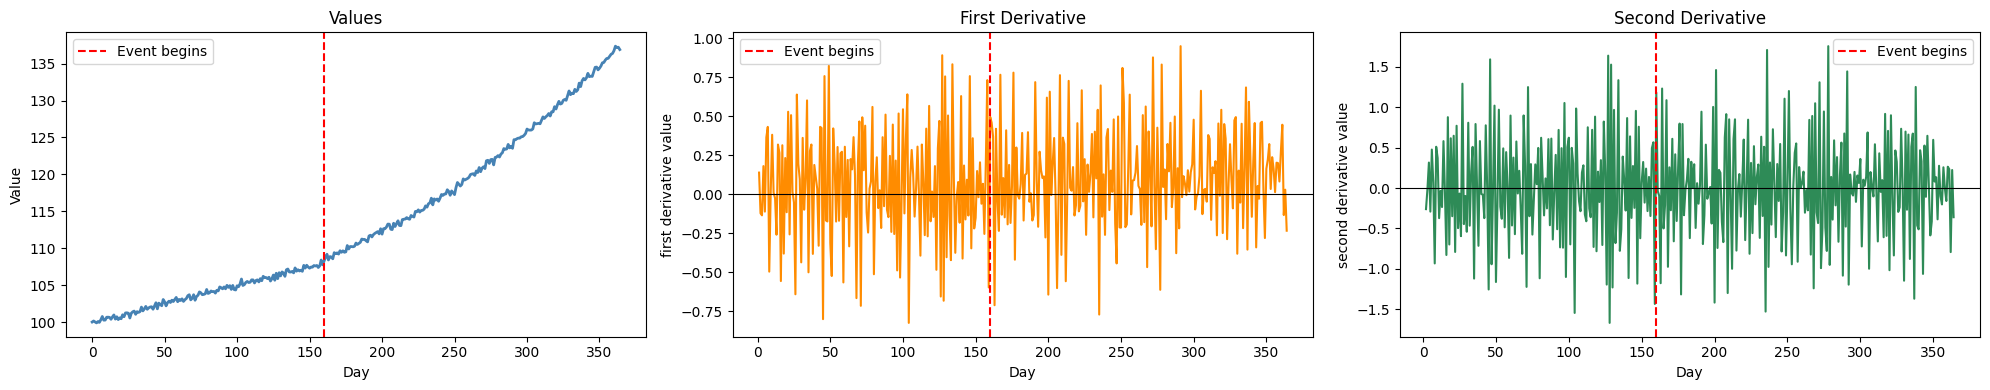

In [29]:
def plot_values_and_derivatives(**kwargs):
    data = compute_event_study_data(**kwargs)

    t = data["t"]
    event_day = data["event_day"]
    value_value = data["value_value"]
    value_return = data["value_return"]

    second_diff = np.diff(value_value, n=2)
    t_second_diff = t[2:]

    fig, axes = plt.subplots(1, 3, figsize=(20, 4))

    ax = axes[0]
    ax.plot(t, value_value, color="steelblue", linewidth=2)
    ax.axvline(event_day, color="red", linestyle="--", label="Event begins")
    ax.set_title("Values")
    ax.set_xlabel("Day")
    ax.set_ylabel("Value")
    ax.legend()

    ax = axes[1]
    ax.plot(t, 100 * value_return, color="darkorange", linewidth=1.5)
    ax.axvline(event_day, color="red", linestyle="--", label="Event begins")
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_title("First Derivative")
    ax.set_xlabel("Day")
    ax.set_ylabel("first derivative value")
    ax.legend()

    ax = axes[2]
    ax.plot(t_second_diff, second_diff, color="seagreen", linewidth=1.5)
    ax.axvline(event_day, color="red", linestyle="--", label="Event begins")
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_title("Second Derivative")
    ax.set_xlabel("Day")
    ax.set_ylabel("second derivative value")
    ax.legend()

    plt.tight_layout()
    plt.show()

plot_values_and_derivatives()

The shift is evident in the plot showing the values. but less evident in the derivative plots. The event is less obvious in the derivative charts as the noise is too high. If we inspect the values plot, we can visually see a change in slope as well as a change in curvature. This is validated by our function as well which introduces these changes in the formula as specified in the parameters. These values have been chosen not because they display well in the charts, but because the event must be subtle enought for the following section in which we compare two different model approaches.

In [ ]:
def t_test_values(
    n_sims=2000,
    n_days=365,
    event_day=180,
    alpha_level=0.05,
    test_window=1,
    **dgp_kwargs
):
    df = event_day - 2
    t_crit = stats.t.ppf(1 - alpha_level / 2, df)

    detections = 0
    effect_estimates = []

    for i in range(n_sims):
        sim_seed = int(i)
        data = compute_event_study_data(
            n_days=n_days, event_day=event_day, seed=sim_seed, **dgp_kwargs
        )
        t = data["t"]
        y = data["value_value"]

        X_pre = sm.add_constant(t[:event_day])
        pre_fit = sm.OLS(y[:event_day], X_pre).fit()

        X_full = sm.add_constant(t)
        resid = y - pre_fit.predict(X_full)
        pre_resid_std = resid[:event_day].std(ddof=2)

        post_resid = resid[event_day:event_day + test_window]
        car = post_resid.mean()
        se = pre_resid_std / np.sqrt(test_window)
        t_stat = car / se

        effect_estimates.append(car)
        if abs(t_stat) > t_crit:
            detections += 1

    power = detections / n_sims
    return {
        "power": power,
    }

In [ ]:
def t_test_full(
    n_sims=2000,
    n_days=365,
    event_day=180,
    alpha_level=0.05,
    test_window=20,
    **dgp_kwargs
):
    chi2_crit = stats.chi2.ppf(1 - alpha_level, df=3)

    detections = 0
    level_estimates = []
    slope_estimates = []
    curv_estimates = []

    for i in range(n_sims):
        sim_seed = int(i)
        data = compute_event_study_data(
            n_days=n_days, event_day=event_day, seed=sim_seed, **dgp_kwargs
        )
        t = data["t"]
        y = data["value_value"]

        X_pre = sm.add_constant(t[:event_day])
        pre_fit = sm.OLS(y[:event_day], X_pre).fit()

        X_full = sm.add_constant(t)
        resid = y - pre_fit.predict(X_full)
        pre_resid_std = resid[:event_day].std(ddof=2)

        end = min(event_day + test_window, n_days)
        days_after = np.arange(end - event_day)
        X_test = np.column_stack([
            np.ones_like(days_after, dtype=float),
            days_after,
            days_after**2,
        ])
        y_test = resid[event_day:end]

        XtX_inv = np.linalg.inv(X_test.T @ X_test)
        beta_hat = XtX_inv @ X_test.T @ y_test

        cov_beta = (pre_resid_std**2) * XtX_inv

        wald_stat = beta_hat @ np.linalg.inv(cov_beta) @ beta_hat

        level_estimates.append(beta_hat[0])
        slope_estimates.append(beta_hat[1])
        curv_estimates.append(beta_hat[2])

        if wald_stat > chi2_crit:
            detections += 1

    power = detections / n_sims
    return {
        "power": power,
    }

In [39]:
result_a = t_test_values(n_sims=2000, event_day=180, test_window=3)
result_b = t_test_full(n_sims=2000, event_day=180, test_window=3)
print("Model (a) power:", result_a["power"])
print("Model (b) power:", result_b["power"])

Model (a) power: 0.9425
Model (b) power: 0.875


Modifying the t-test used in homework 11, to apply to our generated event study, we can compare a model utilizing values only to a model utilizing values, deriviatives, and second derivative. When our test windows, that is the time after the event we are comparing to the time before the event, the models take a bit to ramp up. Eventually, given the generated data, the models reach 1, but using small enough test windows, we can see that model (a), using only values, approaches 1 faster. I believe in this case, this is due to the jump in values being greater than the jump in derivative values.

In terms of deciding which is better, this depends on the dataset. In our case given that the change in values is more notable than any change in slope/second derivative, model (a) is better. If the change in values was more subtle, and there were significant changes in derivative and slope then perhaps model (b) would be *better*.

---

*2. Construct a dataset in which there are three groups whose values each increase discontinuously (suddenly) by the same amount at a shared event; they change in parallel over time, but they have different starting values.  Create a model that combines group fixed effects with an event study, as suggested in the online reading. Explain what you did, how the model works, and how it accounts for both baseline differences and the common event effect.*

In [42]:
np.random.seed(42)
 
groups = ["A", "B", "C"]
baselines = {"A": 10, "B": 20, "C": 30}
times = [-3, -2, -1, 0, 1, 2, 3]
 
true_beta1 = 0.5
true_beta2 = 5.0
true_beta3 = 0.0
noise_sd = 0.5
 
rows = []
for g in groups:
    for t in times:
        after = 1 if t >= 0 else 0
        mean_val = (baselines[g] + true_beta1 * t + true_beta2 * after + true_beta3 * t * after)
        y = mean_val + np.random.normal(0, noise_sd)
        rows.append({"group": g, "t": t, "After": after, "Y": y})
 
df = pd.DataFrame(rows)

model = smf.ols("Y ~ C(group) + t + After + t:After", data=df).fit()
print(model.summary())


                            OLS Regression Results                            
Dep. Variable:                      Y   R-squared:                       0.998
Model:                            OLS   Adj. R-squared:                  0.997
Method:                 Least Squares   F-statistic:                     1203.
Date:                Sat, 15 Aug 2026   Prob (F-statistic):           5.69e-19
Time:                        17:09:17   Log-Likelihood:                -12.160
No. Observations:                  21   AIC:                             36.32
Df Residuals:                      15   BIC:                             42.59
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
Intercept        10.3323      0.477     21.646

I generated the dataset by creating 3 groups (A, B, C) with 3 times (-3, -2, -1) before the event and 4 times (0, 1, 2, 3) after. Using a nested iteration I then populated the rows using set baselines and beta values in the same formula. The baselines are set per the instructions that they change in parallel with different starting values.

The model then utilizes the following formula from the reading:
$$Y_{it} = \beta_i + \beta_1 t + \beta_2 \operatorname{After}_t + \beta_3 \left(t \times \operatorname{After}_t\right) + \epsilon_{it}$$
This is represented using statsmodel formula API, specifically using patsy notation. This equation applies because of the fact that despite there being multiple groups with different starting points (intercepts), they share the same $\beta_1$, $\beta_2$, and $\beta_3$. The different starting points (intercepts) are accounted for by using a fixed effect for each group (represented by term $\beta_i$).

---

### Homework Reflection 12

*Construct a dataset in which prior trends do not hold, and in which this makes the differences-in-differences come out wrong.  Explain why the differences-in-differences estimate of the effect comes out higher or lower than the actual effect.*

In [ ]:
np.random.seed(42)

groups = ["A", "B"]
baselines = {"A": 10, "B": 20}

group_trends = {"A": 2.0, "B": 0.4}

times = [-3, -2, -1, 0, 1, 2, 3]

true_effect = 5.0
noise_sd = 0.5
treated_group = "A"

rows = []
for g in groups:
    for t in times:
        after = 1 if t >= 0 else 0
        treated = 1 if g == treated_group else 0

        mean_val = baselines[g] + group_trends[g] * t
        mean_val += true_effect * after * treated

        y = mean_val + np.random.normal(0, noise_sd)
        rows.append({"group": g, "t": t, "After": after, "Treated": treated, "Y": y})

df = pd.DataFrame(rows)

model = smf.ols("Y ~ Treated + After + Treated:After", data=df).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                      Y   R-squared:                       0.932
Model:                            OLS   Adj. R-squared:                  0.911
Method:                 Least Squares   F-statistic:                     45.36
Date:                Sat, 15 Aug 2026   Prob (F-statistic):           3.95e-06
Time:                        17:40:31   Log-Likelihood:                -25.313
No. Observations:                  14   AIC:                             58.63
Df Residuals:                      10   BIC:                             61.18
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
Intercept        19.3401      1.008     19.185

To explain why the DID estimate is wrong, we can look at how the treatment data is generated. Similar to the previous problems, we start at different baselines. However, we also have different trends for each group. These trends are present even *without* treatment. This is what renders the DID estimate inaccurate, as DID assumes parallel trends. For how this looks specifically with our generated data, we define the treatment effect as 5. In our model, to find the treatment effect, we look at the Treated:After coefficient of our DID regression model which is approximately 11.2. For our DID regression model we used the following formula: $$Y = \beta_0 + \beta_1 \times \text{TreatedGroup} + \beta_2 \times \text{AfterTreatment} + \beta_3 \left(\text{TreatedGroup} \times \text{AfterTreatment}\right) + \epsilon$$ The specific reason it comes out higher in our case, as the treatment group has a larger value trend than the control group. If the treatment group's trend value was lower, then the DID model would have underestimated.

### AI Appendix

**PROMPT**

Generate only code. Modify the function for when errors are highly correlated:
```py
def repeated_ols_simulator_homo(
    num_samples=10,
    num_times=1000,
    beta_0=1.0,
    beta_1=2.0,
    x_sigma=2.0,
    hetero_intercept=1.0,
    hetero_slope=0.5,
    random_seed=42
):
    if num_samples < 3:
        print("Wrong setup: each OLS fit needs at least 3 samples to estimate residual variance.")
        return

    rng = np.random.default_rng(random_seed)

    beta_0_hats = np.empty(num_times)
    beta_1_hats = np.empty(num_times)
    se_beta_1_hats_sm_classical = np.empty(num_times)

    for t in range(num_times):
        X = rng.normal(loc=0.0, scale=x_sigma, size=num_samples)

        sigma_i = hetero_intercept + hetero_slope * np.abs(X)
        epsilon = rng.normal(loc=0.0, scale=1.0, size=num_samples) * sigma_i

        Y = beta_0 + beta_1 * X + epsilon

        X_mean = X.mean()
        Y_mean = Y.mean()
        Sxx = np.sum((X - X_mean) ** 2)

        if Sxx == 0:
            print("Wrong setup: OLS cannot estimate a slope because Var(X) is zero.")
            return

        beta_1_hat = np.sum((X - X_mean) * (Y - Y_mean)) / Sxx
        beta_0_hat = Y_mean - beta_1_hat * X_mean

        beta_0_hats[t] = beta_0_hat
        beta_1_hats[t] = beta_1_hat

        X_design = sm.add_constant(X)
        model = sm.OLS(Y, X_design).fit()
        se_beta_1_hats_sm_classical[t] = model.bse[1]


    beta_1_hat_sample_deviation = beta_1_hats.std(ddof=1)

    mean_se_beta_1_sm_classical = se_beta_1_hats_sm_classical.mean()

    print(f"{'Simulation'}: {beta_1_hat_sample_deviation:.4f}")
    print(f"{'statsmodels OLS'}: {mean_se_beta_1_sm_classical:.4f}")

    diff = abs(beta_1_hat_sample_deviation - mean_se_beta_1_sm_classical)
    avg = (beta_1_hat_sample_deviation + mean_se_beta_1_sm_classical) / 2
    pct_diff = (diff / avg) * 100

    print(f"% diff: {pct_diff:.0f}%")


repeated_ols_simulator_homo(
    num_samples=200,
    num_times=20000,
    beta_0=1.0,
    beta_1=2.0,
    x_sigma=2.0,
    hetero_intercept=1.0,
    hetero_slope=0.5,
    random_seed=42,
)
```

**Response (Claude)**:
```py
def repeated_ols_simulator(
    num_samples=10,
    num_times=1000,
    beta_0=1.0,
    beta_1=2.0,
    x_sigma=2.0,
    hetero_intercept=1.0,
    hetero_slope=0.5,
    rho=0.8,
    random_seed=42
):
    if num_samples < 3:
        print("Wrong setup: each OLS fit needs at least 3 samples to estimate residual variance.")
        return

    rng = np.random.default_rng(random_seed)

    beta_0_hats = np.empty(num_times)
    beta_1_hats = np.empty(num_times)
    se_beta_1_hats_sm_classical = np.empty(num_times)

    for t in range(num_times):
        X = rng.normal(loc=0.0, scale=x_sigma, size=num_samples)

        sigma_i = hetero_intercept + hetero_slope * np.abs(X)

        common_shock = rng.normal(loc=0.0, scale=1.0)
        idio_noise = rng.normal(loc=0.0, scale=1.0, size=num_samples)
        z = np.sqrt(rho) * common_shock + np.sqrt(1 - rho) * idio_noise
        epsilon = z * sigma_i

        Y = beta_0 + beta_1 * X + epsilon

        X_mean = X.mean()
        Y_mean = Y.mean()
        Sxx = np.sum((X - X_mean) ** 2)

        if Sxx == 0:
            print("Wrong setup: OLS cannot estimate a slope because Var(X) is zero.")
            return

        beta_1_hat = np.sum((X - X_mean) * (Y - Y_mean)) / Sxx
        beta_0_hat = Y_mean - beta_1_hat * X_mean

        beta_0_hats[t] = beta_0_hat
        beta_1_hats[t] = beta_1_hat

        X_design = sm.add_constant(X)
        model = sm.OLS(Y, X_design).fit()
        se_beta_1_hats_sm_classical[t] = model.bse[1]

    beta_1_hat_sample_deviation = beta_1_hats.std(ddof=1)
    mean_se_beta_1_sm_classical = se_beta_1_hats_sm_classical.mean()

    print(f"{'Simulation'}: {beta_1_hat_sample_deviation:.4f}")
    print(f"{'statsmodels OLS'}: {mean_se_beta_1_sm_classical:.4f}")

    diff = abs(beta_1_hat_sample_deviation - mean_se_beta_1_sm_classical)
    avg = (beta_1_hat_sample_deviation + mean_se_beta_1_sm_classical) / 2
    pct_diff = (diff / avg) * 100

    print(f"% diff: {pct_diff:.0f}%")
```

**PROMPT**:

Generate only code. The current function is a t test for values only. Modify it to create a model using first and second derivative as well.

```py
def t_test_values(
    n_sims=2000,
    n_days=365,
    event_day=180,
    alpha_level=0.05,
    test_window=1,
    **dgp_kwargs
):
    df = event_day - 2
    t_crit = stats.t.ppf(1 - alpha_level / 2, df)

    detections = 0
    effect_estimates = []

    for i in range(n_sims):
        sim_seed = int(i)
        data = compute_event_study_data(
            n_days=n_days, event_day=event_day, seed=sim_seed, **dgp_kwargs
        )
        t = data["t"]
        y = data["value_value"]

        X_pre = sm.add_constant(t[:event_day])
        pre_fit = sm.OLS(y[:event_day], X_pre).fit()

        X_full = sm.add_constant(t)
        resid = y - pre_fit.predict(X_full)
        pre_resid_std = resid[:event_day].std(ddof=2)

        post_resid = resid[event_day:event_day + test_window]
        car = post_resid.mean()
        se = pre_resid_std / np.sqrt(test_window)
        t_stat = car / se

        effect_estimates.append(car)
        if abs(t_stat) > t_crit:
            detections += 1

    power = detections / n_sims
    return {
        "power": power,
    }
```

**RESPONSE (Claude)**
```py
def t_test_full(
    n_sims=2000,
    n_days=365,
    event_day=180,
    alpha_level=0.05,
    test_window=20,
    **dgp_kwargs
):
    chi2_crit = stats.chi2.ppf(1 - alpha_level, df=3)

    detections = 0
    level_estimates = []
    slope_estimates = []
    curv_estimates = []

    for i in range(n_sims):
        sim_seed = int(i)
        data = compute_event_study_data(
            n_days=n_days, event_day=event_day, seed=sim_seed, **dgp_kwargs
        )
        t = data["t"]
        y = data["value_value"]

        X_pre = sm.add_constant(t[:event_day])
        pre_fit = sm.OLS(y[:event_day], X_pre).fit()

        X_full = sm.add_constant(t)
        resid = y - pre_fit.predict(X_full)
        pre_resid_std = resid[:event_day].std(ddof=2)

        end = min(event_day + test_window, n_days)
        days_after = np.arange(end - event_day)
        X_test = np.column_stack([
            np.ones_like(days_after, dtype=float),
            days_after,
            days_after**2,
        ])
        y_test = resid[event_day:end]

        XtX_inv = np.linalg.inv(X_test.T @ X_test)
        beta_hat = XtX_inv @ X_test.T @ y_test

        cov_beta = (pre_resid_std**2) * XtX_inv

        wald_stat = beta_hat @ np.linalg.inv(cov_beta) @ beta_hat

        level_estimates.append(beta_hat[0])
        slope_estimates.append(beta_hat[1])
        curv_estimates.append(beta_hat[2])

        if wald_stat > chi2_crit:
            detections += 1

    power = detections / n_sims
    return {
        "power": power,
    }
```

**Prompt**
Write only code. Using statsmodal formula api and the generated dataset, create a model using the following formula:

Y subscript i t end subscript equals beta subscript i plus beta subscript 1 t plus beta subscript 2 comma text After end text plus beta subscript 3 left parenthesis t cross times text After end text right parenthesis plus epsilon subscript i t end subscript

code:
```py
np.random.seed(42)
 
groups = ["A", "B", "C"]
baselines = {"A": 10, "B": 20, "C": 30}
times = [-3, -2, -1, 0, 1, 2, 3]
 
true_beta1 = 0.5
true_beta2 = 5.0
true_beta3 = 0.0
noise_sd = 0.5
 
rows = []
for g in groups:
    for t in times:
        after = 1 if t >= 0 else 0
        mean_val = (baselines[g] + true_beta1 * t + true_beta2 * after + true_beta3 * t * after)
        y = mean_val + np.random.normal(0, noise_sd)
        rows.append({"group": g, "t": t, "After": after, "Y": y})
 
df = pd.DataFrame(rows)
```

**RESPONSE (Claude)**
```py
model = smf.ols("Y ~ C(group) + t + After + t:After", data=df).fit()
```